# HU-4 · Análisis Exploratorio de Datos (EDA)

**Índice**
1. Carga de datos
2. Visión general y tipos de datos
3. Valores nulos
4. Variables constantes o sin información
5. Variables binarias
6. Variables categóricas
7. Variables de fecha
8. Variables numéricas: distribuciones
9. Valores atípicos (outliers)
10. Correlaciones
11. Análisis del precio
12. Resumen de hallazgos y plan de limpieza

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

## 1. Carga de datos

In [3]:
RUTA = "../datos/medicamentos_artritis_reumatoide_con_precios.xlsx"
df_raw = pd.read_excel(RUTA)
# Usamos una copia de los datos para no modificar el original
df = df_raw.copy()

## 2. Visión general y tipos de datos

In [4]:
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

Filas: 645 | Columnas: 31


In [5]:
df.head()

,nregistro,nombre,pactivos,labtitular,labcomercializador,cn,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,comercializado,requiere_receta,generico,afecta_conduccion,triangulo_negro,medicamento_huerfano,biosimilar,url_html_ficha_tecnica,url_foto_materiales,num_registros_atc,num_principios_activos,num_excipientes,vias_administracion,volumen_informativo_seguridad,complejidad_desglose_clinico,indicador_riesgo_severo,Estado,Precio de venta al público con IVA,Precio de referencia,Tratamiento de larga duración,Especial control médico
0,61836,ACABEL 4 mg COMPRIMIDOS RECUBIERTOS CON PELICULA,LORNOXICAM,Grünenthal Pharma S.A.,Grünenthal Pharma S.A.,664706,4 mg lornoxicam,COMPRIMIDO,893973600000,1.650384e+12,0,1,0,0,0,0,0,https://cima.aemps.es/cima/dochtml/ft/61836/FT...,https://cima.aemps.es/cima/fotos/thumbnails/ma...,3,1,0,VÍA ORAL,1318,1,6,BAJA GENERAL,2.50,NaN,NO,NO
1,61837,ACABEL 8 mg COMPRIMIDOS RECUBIERTOS CON PELICULA,LORNOXICAM,Grünenthal Pharma S.A.,Grünenthal Pharma S.A.,664698,8 mg,COMPRIMIDO,893973600000,1.650384e+12,0,1,0,0,0,0,0,https://cima.aemps.es/cima/dochtml/ft/61837/FT...,https://cima.aemps.es/cima/fotos/thumbnails/ma...,3,1,0,VÍA ORAL,1319,1,6,BAJA GENERAL,4.51,NaN,NO,NO
2,69223,ACECLOFENACO CINFA 100 mg COMPRIMIDOS RECUBIER...,ACECLOFENACO,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,659777,100 mg,COMPRIMIDO,1186610400000,NaN,1,1,1,0,0,0,0,https://cima.aemps.es/cima/dochtml/ft/69223/FT...,https://cima.aemps.es/cima/fotos/thumbnails/ma...,3,1,0,VÍA ORAL,1127,1,8,ALTA,2.83,2.83,NO,NO
3,71437,ACECLOFENACO NORMON 100 mg COMPRIMIDOS RECUBIE...,ACECLOFENACO,Laboratorios Normon S.A.,Laboratorios Normon S.A.,663991,100 mg,COMPRIMIDO,1254261600000,NaN,1,1,1,0,0,0,0,https://cima.aemps.es/cima/dochtml/ft/71437/FT...,https://cima.aemps.es/cima/fotos/thumbnails/ma...,3,1,0,VÍA ORAL,1124,1,8,ALTA,2.83,2.83,NO,NO
4,79696,ACECLOFENACO STADA 100 MG COMPRIMIDOS RECUBIER...,ACECLOFENACO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,706012,100 mg,COMPRIMIDO,1427666400000,NaN,1,1,1,0,0,0,0,https://cima.aemps.es/cima/dochtml/ft/79696/FT...,https://cima.aemps.es/cima/fotos/thumbnails/ma...,3,1,0,VÍA ORAL,1100,1,9,ALTA,2.83,2.83,NO,NO


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 645 entries, 0 to 644
Data columns (total 31 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   nregistro                           645 non-null    int64  
 1   nombre                              645 non-null    object 
 2   pactivos                            645 non-null    object 
 3   labtitular                          645 non-null    object 
 4   labcomercializador                  645 non-null    object 
 5   cn                                  645 non-null    int64  
 6   dosis                               645 non-null    object 
 7   forma_farmaceutica_simplificada     645 non-null    object 
 8   estado_aut                          645 non-null    int64  
 9   estado_rev                          147 non-null    float64
 10  comercializado                      645 non-null    int64  
 11  requiere_receta                     645 non-n

In [7]:
# Resumen por columna
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "unicos": df.nunique(),
    "duplicados": df.apply(lambda col: col.dropna().duplicated().sum()),
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(1),
})
resumen

,tipo,unicos,duplicados,nulos,pct_nulos
nregistro,int64,645,0,0,0.0
nombre,object,635,10,0,0.0
pactivos,object,60,585,0,0.0
labtitular,object,123,522,0,0.0
labcomercializador,object,102,543,0,0.0
cn,int64,645,0,0,0.0
dosis,object,163,482,0,0.0
forma_farmaceutica_simplificada,object,12,633,0,0.0
estado_aut,int64,472,173,0,0.0
estado_rev,float64,138,9,498,77.2


### Problemas de tipo detectados

**`nregistro:`** Aparece como tipo entero y debería ser un string, puede que se hayan perdido 0 a la izquierda en el proceso. Se puede comprobar mirando la URL de ficha técnica.

In [8]:
# str.extract(r"...()...) recoge solamente lo que se encuentra dentro del paréntesis de la expresión regular
id_url = df["url_html_ficha_tecnica"].str.extract(r"/ft/(\d+)/")[0]

# Se busca en que filas no coincide este número con el nregistro para devolverle el valor original en caso de que falle alguno
perdida_ceros = df[id_url != df["nregistro"].astype(str)]
print("Registros con error:", len(perdida_ceros))

Registros con error: 10


In [9]:
# Comprobamos si el problema es el que pensamos y no otro
perdida_ceros[['nregistro','url_html_ficha_tecnica']]

,nregistro,url_html_ficha_tecnica
91,3256003,https://cima.aemps.es/cima/dochtml/ft/03256003...
181,7389008,https://cima.aemps.es/cima/dochtml/ft/07389008...
183,7389001,https://cima.aemps.es/cima/dochtml/ft/07389001...
199,9546001,https://cima.aemps.es/cima/dochtml/ft/09546001...
425,3256008,https://cima.aemps.es/cima/dochtml/ft/03256008...
513,9604001,https://cima.aemps.es/cima/dochtml/ft/09604001...
514,9604010,https://cima.aemps.es/cima/dochtml/ft/09604010...
515,9604005,https://cima.aemps.es/cima/dochtml/ft/09604005...
622,8492001,https://cima.aemps.es/cima/dochtml/ft/08492001...
623,8492003,https://cima.aemps.es/cima/dochtml/ft/08492003...


In [10]:
# Al haber 10 errores, se va a usar la lista de id_url pasado a string para rellenar la columna de nregistro
df["nregistro"] = id_url.astype(str)
# Comprobar el primer registro que tiene que aparecer con un cero delante
print(df.iloc[91])

nregistro                                                                      03256003
nombre                                HUMIRA 40 mg SOLUCION INYECTABLE EN JERINGA PR...
pactivos                                                                     ADALIMUMAB
labtitular                                             Abbvie Deutschland Gmbh & Co. Kg
labcomercializador                                                 Abbvie Spain, S.L.U.
cn                                                                               954065
dosis                                                                             40 mg
forma_farmaceutica_simplificada                                              INYECTABLE
estado_aut                                                                1064786400000
estado_rev                                                              1764855180000.0
comercializado                                                                        0
requiere_receta                 

In [11]:
# Revisar que el tipo de dato se haya cambiado a texto (object)
df['nregistro'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 645 entries, 0 to 644
Series name: nregistro
Non-Null Count  Dtype 
--------------  ----- 
645 non-null    object
dtypes: object(1)
memory usage: 5.2+ KB


- **`cn`** es un identificador (Código Nacional) y no una cantidad. Debe tratarse como texto.

In [12]:
# Los códigos nacionales tienen que tener longitud 6,
# si existe alguno con longitud menor puede resultar en que no haya recibido datos
# de precios al cruzar con el csv nomenclator
df["cn"].astype(str).str.len().value_counts()

cn
6    645
Name: count, dtype: int64

- **`dosis`** es texto libre con unidades en formato de texto, se pretenden convertir todos los valores a mg.

In [13]:
# Valores únicos de dosis
print("Valores distintos de dosis:", df["dosis"].nunique())

# Ejemplos de datos que contienen MG (sin tener en cuenta mayúsculas)
ejemplos = df["dosis"][df["dosis"].str.contains("mg", case=False, na=False)]
print(ejemplos.drop_duplicates().head(20).tolist())

Valores distintos de dosis: 163
['4 mg lornoxicam', '8 mg', '100 mg', '120 mg etoricoxib', '30 mg etoricoxib', '60 mg etoricoxib', '90 mg etoricoxib', '373 MG', '20 mg', '40 mg', '120 mg', '30 MG', '60 mg', '90 mg', '200 mg', '50 MG', '50MG', '200 mg celecoxib', '200 MG', '6 mg / 7,89 mg']


In [14]:
# Sacar los números que vayan delante de MG o G (*1000) para unificar las unidades.
# El resto de los valores se pasaran a desconocido
dosis_txt = df["dosis"].str.lower()
# Extraer los números que van antes de los "mg"
dosis_mg = dosis_txt.str.extract(r"(\d+(?:[.,]\d+)?)\s*mg\b")[0]
# Quitar el punto de los valores que contienen 3 cifras despues del punto (separadores de miles)
# porque con un replace normal nos cargariamos las dosis que usan el punto (.) como decimal
dosis_mg = dosis_mg.str.replace(r"^(\d{1,3})\.(\d{3})$", r"\1\2", regex=True)
# Ahora quitamos las comas por puntos
dosis_mg = dosis_mg.str.replace(",", ".", regex=False).astype(float)

# Ahora con los valores que tienen G como unidad y se multiplican por 1000
dosis_g = dosis_txt.str.extract(r"(\d+(?:[.,]\d+)?)\s*g\b")[0]
dosis_g = dosis_g.str.replace(",", ".", regex=False).astype(float) * 1000

In [15]:
print("Valores en mg:", dosis_mg.notna().sum())
print("Valores en g: ", dosis_g.notna().sum())

Valores en mg: 635
Valores en g:  5


In [16]:
dosis_unificada = dosis_mg.fillna(dosis_g)
len(dosis_unificada)

645

In [17]:
# En lugar de sobreescribir la columna, para mantener trazabilidad se crea una nueva columna
df["dosis_mg"] = dosis_unificada.astype(float).where(dosis_unificada.notna())

- **`estado_aut` / `estado_rev`** son timestamps en **milisegundos** desde 1970. Los valores negativos corresponden a fechas anteriores a 1970.

In [18]:
df["estado_aut"] = (pd.to_datetime(df["estado_aut"], unit="ms", utc=True)
                   .dt.tz_convert("Europe/Madrid")
                   .dt.tz_localize(None)
                   .dt.normalize())

df["estado_rev"] = (pd.to_datetime(df["estado_rev"], unit="ms", utc=True)
                   .dt.tz_convert("Europe/Madrid")
                   .dt.tz_localize(None)
                   .dt.normalize())

In [19]:
# Comprobar resultados
df[["estado_aut", "estado_rev"]].info()
df[["estado_aut", "estado_rev"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 645 entries, 0 to 644
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   estado_aut  645 non-null    datetime64[ns]
 1   estado_rev  147 non-null    datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 10.2 KB


,estado_aut,estado_rev
count,645,147
mean,2011-03-13 07:28:44.651162624,2024-03-11 18:17:08.571428608
min,1958-02-01 00:00:00,2021-10-05 00:00:00
25%,2007-07-25 00:00:00,2022-09-04 12:00:00
50%,2015-07-30 00:00:00,2024-03-08 00:00:00
75%,2018-09-21 00:00:00,2025-05-29 00:00:00
max,2026-08-07 00:00:00,2026-08-03 00:00:00


## 3. Valores nulos

Análisis de valores nulos en las columnas del DataFrame.

                                    nulos   pct
estado_rev                            498  77.2
url_foto_materiales                   430  66.7
Precio de referencia                  329  51.0
Estado                                306  47.4
Precio de venta al público con IVA    306  47.4
Tratamiento de larga duración         306  47.4
Especial control médico               306  47.4
dosis_mg                                5   0.8


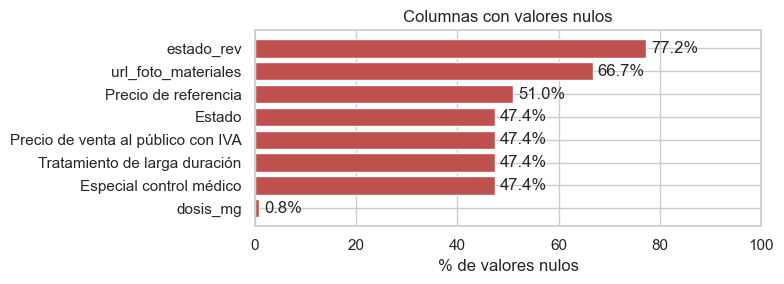

In [20]:
# Gráfico con el porcentage de nulos que tienen aquellas columnas que contienen nulos
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pct = (nulos / len(df) * 100).round(1)
tabla_nulos = pd.DataFrame({"nulos": nulos, "pct": pct})
print(tabla_nulos)

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(pct.index, pct.values, color="#c0504d")
for i, v in enumerate(pct.values):
    ax.text(v + 1, i, f"{v}%", va="center")
ax.set_xlim(0, 100)
ax.set_xlabel("% de valores nulos")
ax.set_title("Columnas con valores nulos")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Análisis de valores nulos en el precio** 
Comprobar si los valores que no tienen precio pertenecen a algún grupo concreto.
- Opción 1: Dividir entre las diferentes Formulas Farmacéuticas
- Opción 2: Si pertenece o no al grupo de Biosimilar

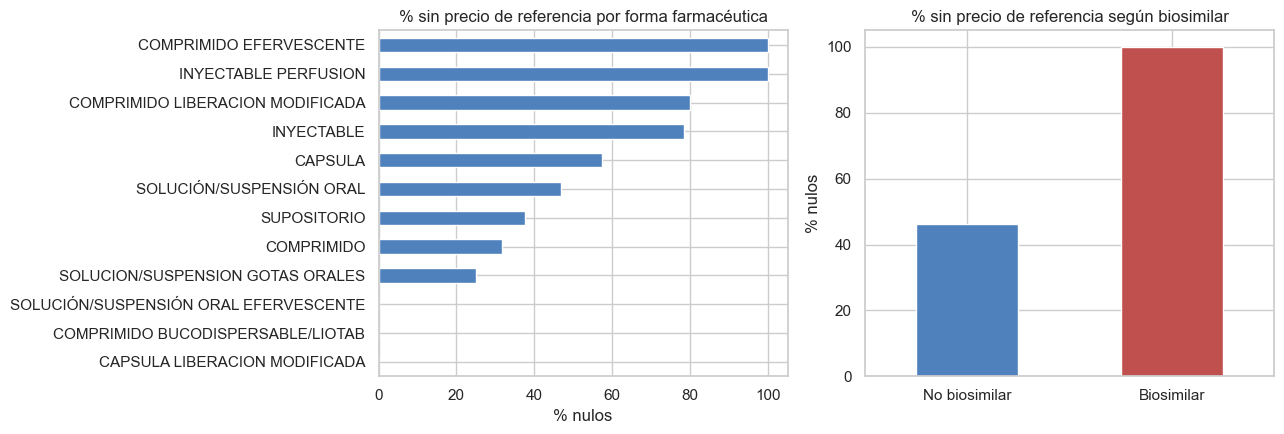

In [ ]:
# Como indicador de si una fila tiene un precio de referencia se utiliza
# "Precio de venta al público con IVA" al contener menos valores nulos que "Precio de Referencia"
df["precio_nulo"] = df["Precio de venta al público con IVA"].isna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

(df.groupby("forma_farmaceutica_simplificada")["precio_nulo"].mean() * 100) \
    .sort_values().plot.barh(ax=axes[0], color="#4f81bd")
axes[0].set_title("% sin precio de referencia por forma farmacéutica")
axes[0].set_xlabel("% nulos"); axes[0].set_ylabel("")

(df.groupby("biosimilar")["precio_nulo"].mean() * 100) \
    .rename({0: "No biosimilar", 1: "Biosimilar"}).plot.bar(ax=axes[1], color=["#4f81bd", "#c0504d"])
axes[1].set_title("% sin precio de referencia según biosimilar")
axes[1].set_ylabel("% nulos"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Conclusiones sobre nulos**

- **`estado_rev`**: 77,2 % de nulos. Indica que el medicamento no ha tenido revisión. Se puede crear una variable booleana que indique si tiene revisión o no.
- **`url_foto_materiales`**: 66,7 % de nulos. Esta variable no tiene valor analítico. Puede ser interesante para más adelante cuando se cree una visualización con los datos de cada producto, pero no para el modelo.
- **`Precio de referencia`**: 51 % de nulos. Los valores se agrupan en difierentes tipos de medicamentos y no parece tener sentido analítico rellenar estos valores con posibles medias generales al pertenecer a grupos distintos de medicamentos.

## 4. Variables constantes o sin información
Algunas de las variables tienen un valor igual para todos los medicamentos. Esto significa que estas variables no tienen valor diferencial para hacer un modelo más adelante.

In [22]:
# Sacar las columnas que tienen un solo valor único y comprobar cuál es y por qué
constantes = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Columnas con un único valor:")
for c in constantes:
    print(f"  - {c}: {df[c].iloc[0]}")

Columnas con un único valor:
  - requiere_receta: 1
  - medicamento_huerfano: 0
  - num_registros_atc: 3
  - num_excipientes: 0


Estas son las columnas y sus valores:

- **`requiere_receta`**: todos los medicamentos para la AR requieren receta.
- **`medicamento_huerfano`**: ninguno es huérfano.
- **`num_registros_atc`**: siempre vale 3 porque cuenta los niveles del código ATC, no códigos distintos.
- **`num_excipientes`**: siempre vale 0.

## 5. Variables binarias

In [23]:
df['Especial control médico'].unique()

array(['NO', nan], dtype=object)

In [24]:
df['Tratamiento de larga duración'].unique()

array(['NO', nan, 'SI'], dtype=object)

In [25]:
df['Estado'].unique()

array(['BAJA GENERAL', 'ALTA', nan, 'BAJA POR NO COMERCIALIZAR',
       'SUSPENSION TEMPORAL GENERAL'], dtype=object)

In [26]:
# Cambiar las variables que utilizan Si y No a tipo booleano con 1 o 0
mapeo_sino = {
    'SI': 1,
    'NO': 0
}
df['Especial control médico'] = df['Especial control médico'].map(mapeo_sino)
df['Tratamiento de larga duración'] = df['Tratamiento de larga duración'].map(mapeo_sino)

In [27]:
# Comprobar el tipo de las columnas
df[['Estado','Especial control médico','Tratamiento de larga duración']].dtypes

Estado                            object
Especial control médico          float64
Tratamiento de larga duración    float64
dtype: object

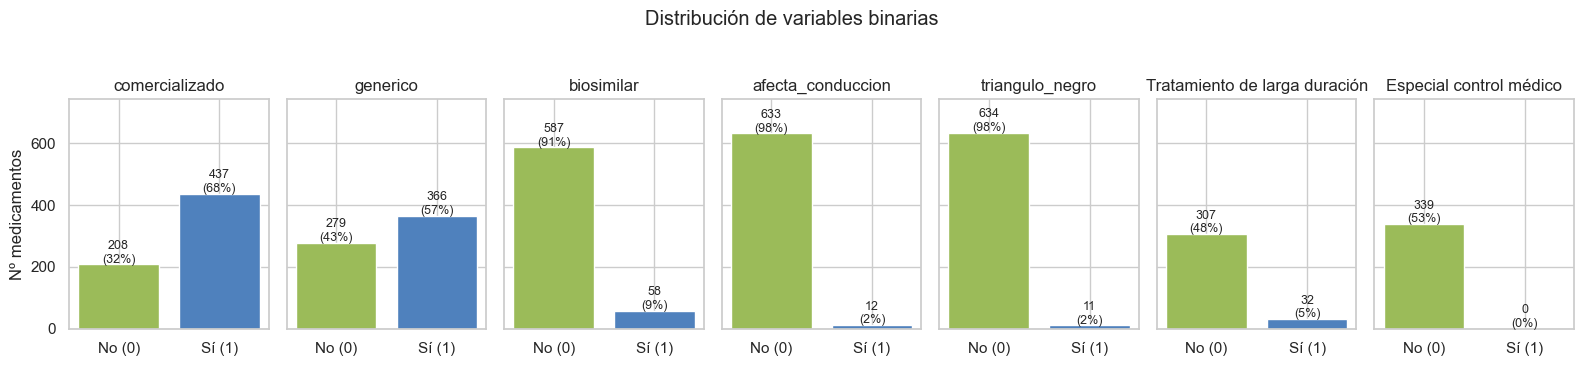

In [28]:
# Definir las columnas binarias
binarias = ["comercializado", "generico", "biosimilar", "afecta_conduccion", "triangulo_negro", "Tratamiento de larga duración", "Especial control médico"]

# Crear un plot para ver la distribución de las variables numéricas
fig, axes = plt.subplots(1, len(binarias), figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, binarias):
    conteo = df[col].value_counts().reindex([0, 1], fill_value=0)
    ax.bar(["No (0)", "Sí (1)"], conteo.values, color=["#9bbb59", "#4f81bd"])
    for i, v in enumerate(conteo.values):
        ax.text(i, v + 5, f"{v}\n({v/len(df):.0%})", ha="center", fontsize=9)
    ax.set_title(col)
    ax.set_ylim(0, len(df) * 1.15)
axes[0].set_ylabel("Nº medicamentos")
plt.suptitle("Distribución de variables binarias", y=1.04)
plt.tight_layout()
plt.show()

- El 68 % de los medicamentos está comercializado y el 57 % son genéricos (EFG).
- `afecta_conduccion` (12 casos), `triangulo_negro` (11) y `biosimilar` (58) están desbalanceados.
- `Estado` tiene un buen balance pero incluye nulos cerca del 50% del total de los datos.
- `Tratamiento de larga duración` (92) y `Especial control médico` (0) están desbalanceadas pero incluyen también una cantidad de nulos cerca del 50%.

## 6. Variables categóricas

In [29]:
categoricas = ["forma_farmaceutica_simplificada", "vias_administracion", "pactivos", "labtitular", "labcomercializador", "Estado"]
df[categoricas].nunique().to_frame("valores_distintos")

,valores_distintos
forma_farmaceutica_simplificada,12
vias_administracion,15
pactivos,60
labtitular,123
labcomercializador,102
Estado,4


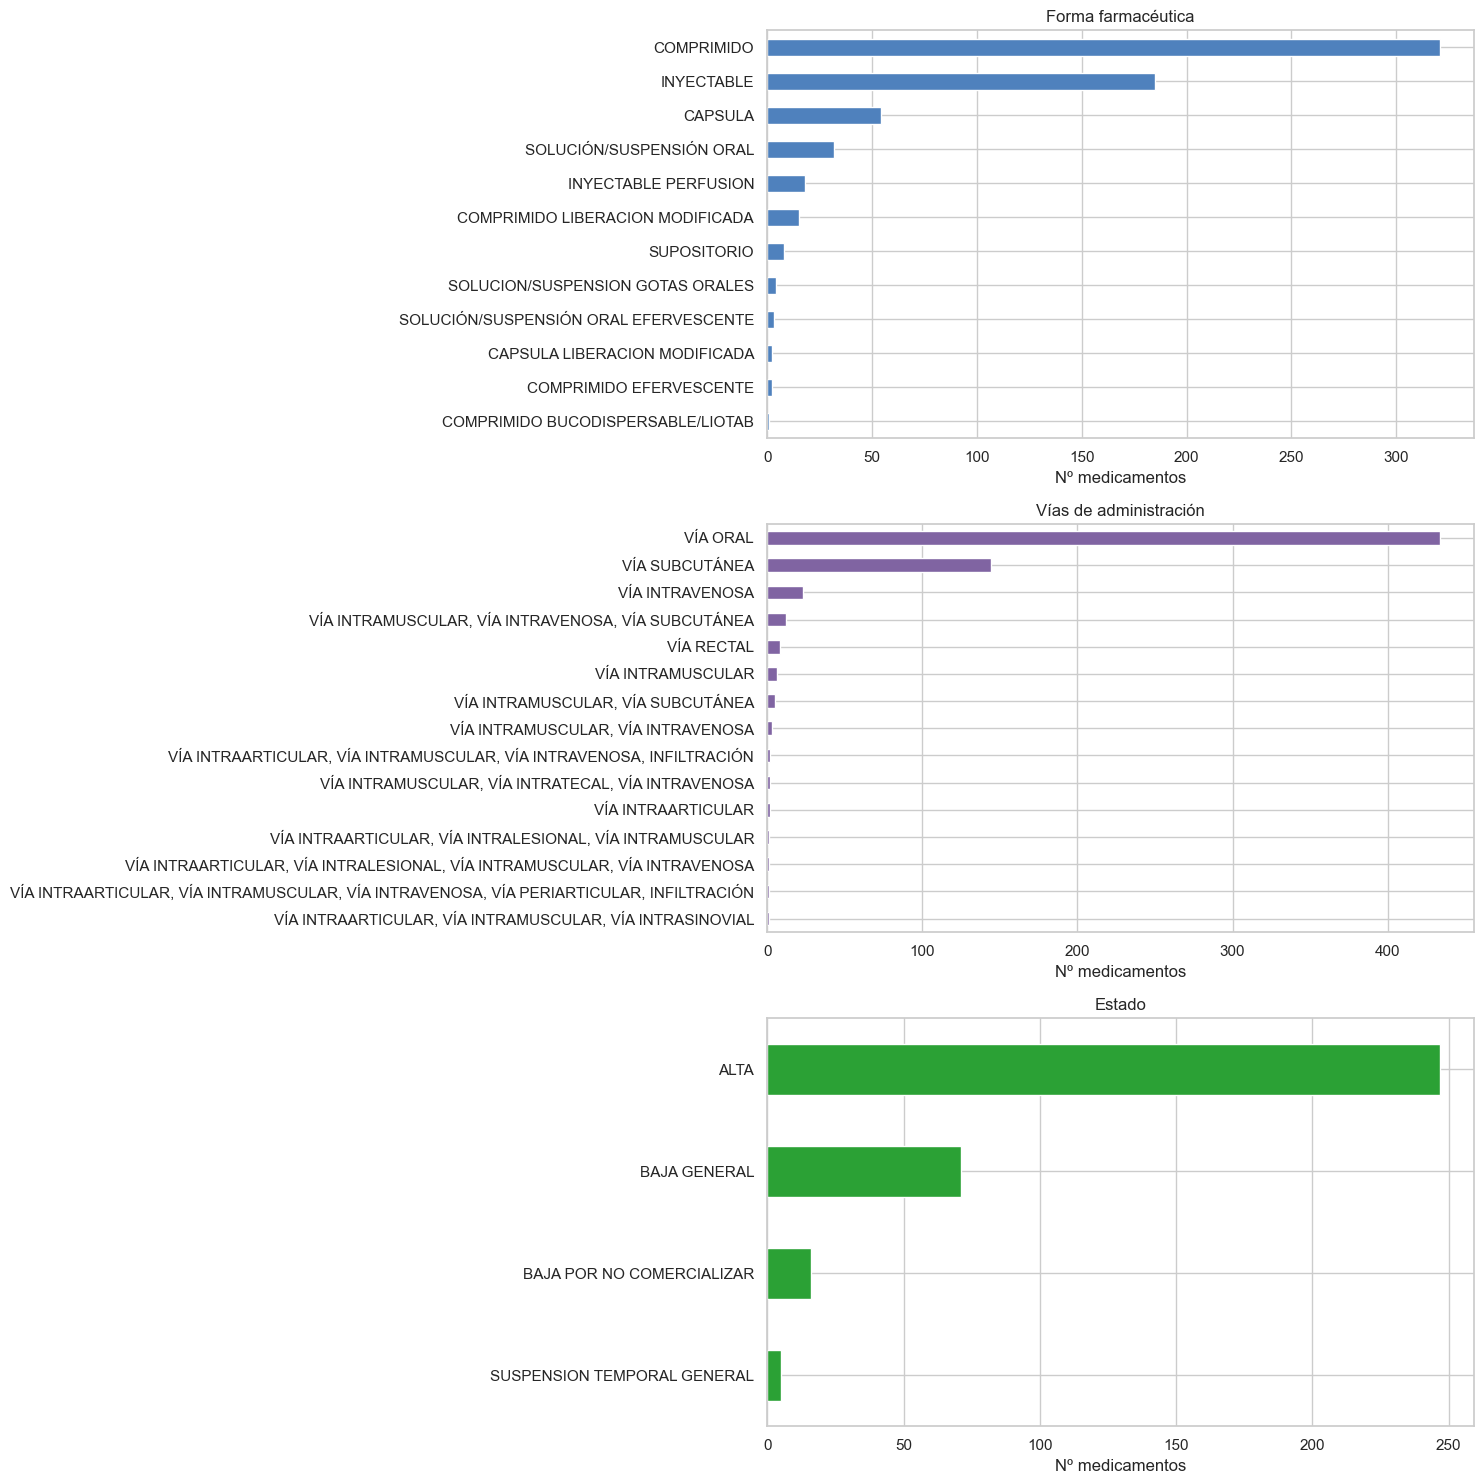

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))

df["forma_farmaceutica_simplificada"].value_counts().sort_values() \
    .plot.barh(ax=axes[0], color="#4f81bd")
axes[0].set_title("Forma farmacéutica"); axes[0].set_xlabel("Nº medicamentos"); axes[0].set_ylabel("")

df["vias_administracion"].value_counts().sort_values() \
    .plot.barh(ax=axes[1], color="#8064a2")
axes[1].set_title("Vías de administración"); axes[1].set_xlabel("Nº medicamentos"); axes[1].set_ylabel("")

df["Estado"].value_counts().sort_values() \
    .plot.barh(ax=axes[2], color="#2ba135")
axes[2].set_title("Estado"); axes[2].set_xlabel("Nº medicamentos"); axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

**Inconsistencias detectadas**

- `Forma farmacéutica`: hay variantes con y sin tilde (`SOLUCIÓN/SUSPENSIÓN ORAL` frente a `SOLUCION/SUSPENSION GOTAS ORALES`) y varias categorías con muy pocos casos. Pueden agruparse de forma lógica según sus valores (oral sólido, oral líquido, inyectable, perfusión, rectal).Al no ser una gran cantidad de opcinoes puede valer la pena mantenerlas como están.
- `Vías de administración`: una misma celda contiene varias vías separadas por comas. Conviene separar estos valores eliminando tildes o crear columnas para los diferentes tratamientos que sean booleanos con 0 y 1 ya que un medicamento puede tener varias opciones. Otra opción puede ser cambiar al número de opciones que tiene de vía, pero esta opción puede no añadir valor real al modelo.
- `Estado`: Las opciones de estado no nulas se pueden dividir en dos grupos: ALTAS y BAJA/SUSPENSION.

In [31]:
df['vias_administracion'].unique()

array(['VÍA ORAL', 'VÍA INTRAMUSCULAR, VÍA INTRAVENOSA', 'VÍA SUBCUTÁNEA',
       'VÍA INTRAARTICULAR, VÍA INTRALESIONAL, VÍA INTRAMUSCULAR',
       'VÍA INTRAMUSCULAR', 'VÍA INTRAVENOSA',
       'VÍA INTRAMUSCULAR, VÍA INTRATECAL, VÍA INTRAVENOSA',
       'VÍA INTRAARTICULAR, VÍA INTRAMUSCULAR, VÍA INTRASINOVIAL',
       'VÍA RECTAL',
       'VÍA INTRAARTICULAR, VÍA INTRAMUSCULAR, VÍA INTRAVENOSA, INFILTRACIÓN',
       'VÍA INTRAMUSCULAR, VÍA INTRAVENOSA, VÍA SUBCUTÁNEA',
       'VÍA INTRAARTICULAR',
       'VÍA INTRAARTICULAR, VÍA INTRAMUSCULAR, VÍA INTRAVENOSA, VÍA PERIARTICULAR, INFILTRACIÓN',
       'VÍA INTRAARTICULAR, VÍA INTRALESIONAL, VÍA INTRAMUSCULAR, VÍA INTRAVENOSA',
       'VÍA INTRAMUSCULAR, VÍA SUBCUTÁNEA'], dtype=object)

In [32]:
# Valores distintos separados por comas en cada fila
vias_distintas = df['vias_administracion'].str.get_dummies(sep=', ')

# Concatenar las columnas nuevas a los valores del df
df = pd.concat([df, vias_distintas], axis=1)

# Comprobar el resultado de una fila que tienen más de ua via
print(f"Valores esperados: {df['vias_administracion'].iloc[9]}")
print(f"Resultados:\n{vias_distintas.iloc[9]}")

Valores esperados: VÍA INTRAMUSCULAR, VÍA INTRAVENOSA
Resultados:
INFILTRACIÓN          0
VÍA INTRAARTICULAR    0
VÍA INTRALESIONAL     0
VÍA INTRAMUSCULAR     1
VÍA INTRASINOVIAL     0
VÍA INTRATECAL        0
VÍA INTRAVENOSA       1
VÍA ORAL              0
VÍA PERIARTICULAR     0
VÍA RECTAL            0
VÍA SUBCUTÁNEA        0
Name: 9, dtype: int64


In [33]:
# Camabiar los valores de la columna Estado entre ALTA (1) y otros valores no nulos (0) y guardar como booleano
mapeo_estado = {
    'BAJA GENERAL': 0,
    'BAJA POR NO COMERCIALIZAR': 0,
    'SUSPENSION TEMPORAL GENERAL':0,
    'ALTA':1
}
df['Estado'] = df['Estado'].map(mapeo_estado).astype("boolean")

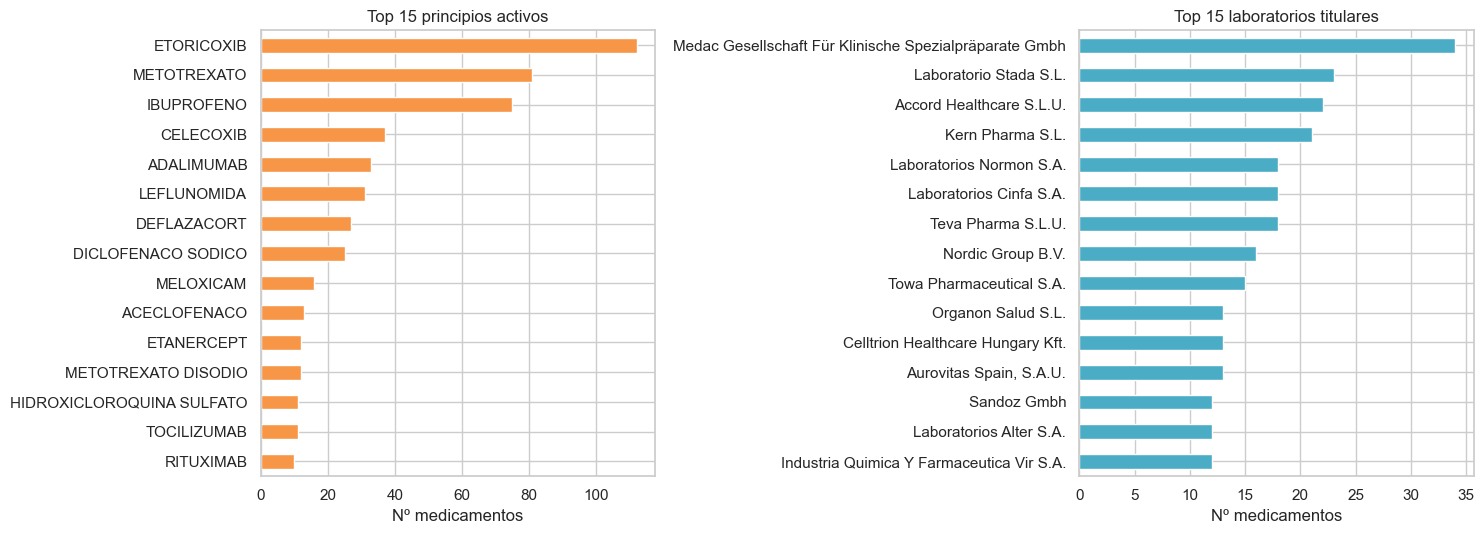

In [34]:
# Gráfico para sacar los valores de los 15 principios activos y los 15 laboratorios más comunes
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

df["pactivos"].value_counts().head(15).sort_values() \
    .plot.barh(ax=axes[0], color="#f79646")
axes[0].set_title("Top 15 principios activos"); axes[0].set_xlabel("Nº medicamentos"); axes[0].set_ylabel("")

df["labtitular"].value_counts().head(15).sort_values() \
    .plot.barh(ax=axes[1], color="#4bacc6")
axes[1].set_title("Top 15 laboratorios titulares"); axes[1].set_xlabel("Nº medicamentos"); axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [35]:
# Variantes de un mismo principio activo
for comunes in ["METOTREXATO", "IBUPROFENO", "NAPROXENO", "HIDROCORTISONA"]:
    variantes = df.loc[df["pactivos"].str.contains(comunes, na=False), "pactivos"].value_counts()
    print(f"{comunes}:", variantes.to_dict())

METOTREXATO: {'METOTREXATO': 81, 'METOTREXATO DISODIO': 12, 'METOTREXATO SODIO': 2}
IBUPROFENO: {'IBUPROFENO': 75, 'IBUPROFENO ARGININA': 6, 'IBUPROFENO LISINA': 2}
NAPROXENO: {'NAPROXENO': 7, 'NAPROXENO SODICO': 7, 'NAPROXENO, ESOMEPRAZOL MAGNESIO TRIHIDRATO': 4, 'NAPROXENO, ESOMEPRAZOL MAGNESICO': 1, 'ESOMEPRAZOL MAGNESIO TRIHIDRATO, NAPROXENO': 1}
HIDROCORTISONA: {'HIDROCORTISONA FOSFATO SODIO': 2, 'HIDROCORTISONA SUCCINATO SODIO': 1}


- Los tres valores más comunes representan cerca del 40 % del catálogo.
- `pactivos` mezcla sales de un posible mismo fármaco (`METOTREXATO` / `METOTREXATO DISODIO`). Hay que entender si agruparlas implica errores ya que realmente no sean medicamentos con un mismo objetivo. Por el momento no se van a agrupar.
- `labtitular` tiene más de 120 valores distintos, con una cardinalidad demasiado alta para usarla directamente en el modelo.

## 7. Variables de fecha

In [36]:
# Cambiar las variabels de revision a tipo fecha y comprobar si hay revisiones que sean antes de las autorizaciones (sería un error)
df["estado_aut"] = pd.to_datetime(df["estado_aut"], unit="ms")
df["estado_rev"] = pd.to_datetime(df["estado_rev"], unit="ms")
x = (df["estado_rev"] < df["estado_aut"]).sum()
fecha_aut_min = df["estado_aut"].min()
fecha_aut_max = df["estado_aut"].max()
print(f"Revisiones anteriores a la autorización: {x}")
print(f"Fecha mínima autorización: {fecha_aut_min}")
print(f"Fecha máxima autorización: {fecha_aut_max}")
fecha_rev_min = df["estado_rev"].min()
fecha_rev_max = df["estado_rev"].max()
print(f"Fecha mínima revisión: {fecha_rev_min}")
print(f"Fecha máxima revisión: {fecha_rev_max}")

Revisiones anteriores a la autorización: 0
Fecha mínima autorización: 1958-02-01 00:00:00
Fecha máxima autorización: 2026-08-07 00:00:00
Fecha mínima revisión: 2021-10-05 00:00:00
Fecha máxima revisión: 2026-08-03 00:00:00


- Las fechas son coherentes: ninguna revisión es anterior a su autorización.
- Para el modelo puede ser más útil una variable numérica como `antiguedad_anios` que la fecha en sí. Aunque puede no tener valor igualmente.

## 8. Variables numéricas: distribuciones

In [37]:
numericas = ["volumen_informativo_seguridad", "complejidad_desglose_clinico",
             "indicador_riesgo_severo", "Precio de venta al público con IVA", "Precio de referencia", "num_principios_activos"]
df[numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
volumen_informativo_seguridad,645.0,1585.73,634.23,244.00,1084.0,1536.00,1855.00,3927.00
complejidad_desglose_clinico,645.0,4.34,8.06,0.00,0.0,1.00,3.00,38.00
indicador_riesgo_severo,645.0,20.04,17.86,0.00,11.0,16.00,18.00,114.00
Precio de venta al público con IVA,339.0,11.21,16.84,0.17,2.5,5.37,16.11,167.48
Precio de referencia,316.0,11.55,17.34,0.17,2.5,5.37,16.11,167.48
num_principios_activos,645.0,1.02,0.14,1.00,1.0,1.00,1.00,3.00


- Al tener diferentes escalas, para aplicar el modelo de KNN se pueden estandarizar las variables numéricas para evitar que puedan tener más peso en el modelo aquellas que tienen mayor escala.
- Para las variables numéricas que usan enteros, los valores no hace falta cambiarlos de ninguna forma ya que poseen un orden con valor (`complejidad_desglose_clinico`, `indicador_riesgo_severo`, `num_principios_activos`).

## 9. Correlaciones

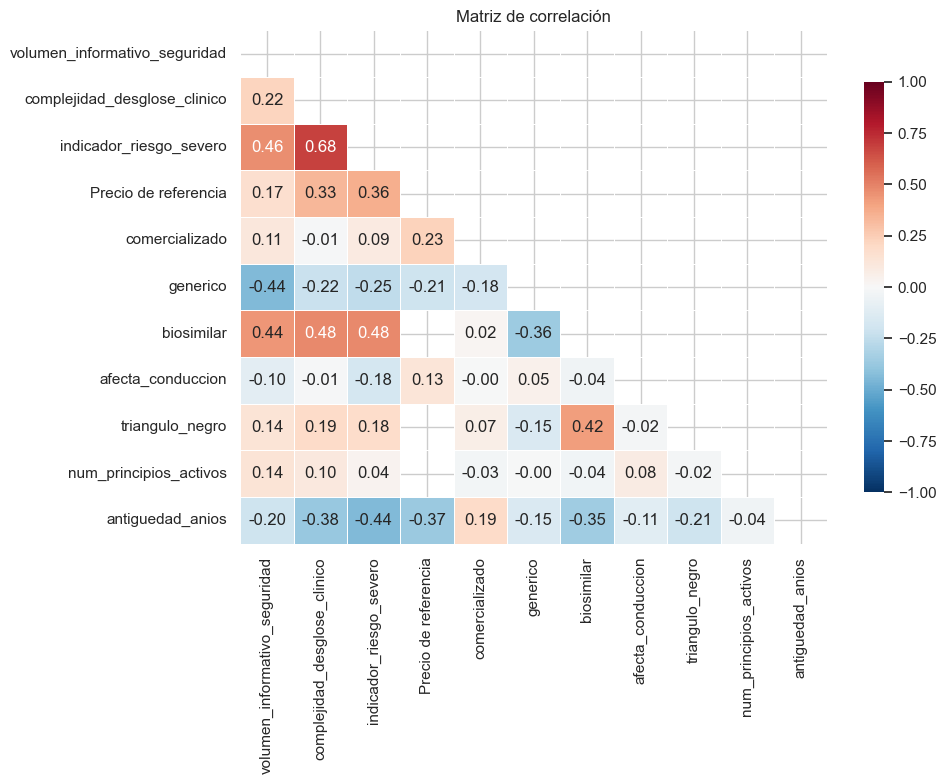

In [38]:
cols_corr = ["volumen_informativo_seguridad", "complejidad_desglose_clinico", "indicador_riesgo_severo",
             "Precio de referencia", "comercializado", "generico", "biosimilar",
             "afecta_conduccion", "triangulo_negro", "num_principios_activos"]
df["antiguedad_anios"] = (pd.Timestamp.today() - df["estado_aut"]).dt.days / 365.25
cols_corr.append("antiguedad_anios")

corr = df[cols_corr].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

In [39]:
# Crear una variable que divida los datos entre inyectable y no inyectable para buscar patrones
# En caso de ser relevante en la gráfica puede usarse para el modelo más adelante
df['tipo_admin'] = np.where(
    df["forma_farmaceutica_simplificada"].str.contains("INYECTABLE", case=False, na=False),
    "Inyectable", "No inyectable"
)

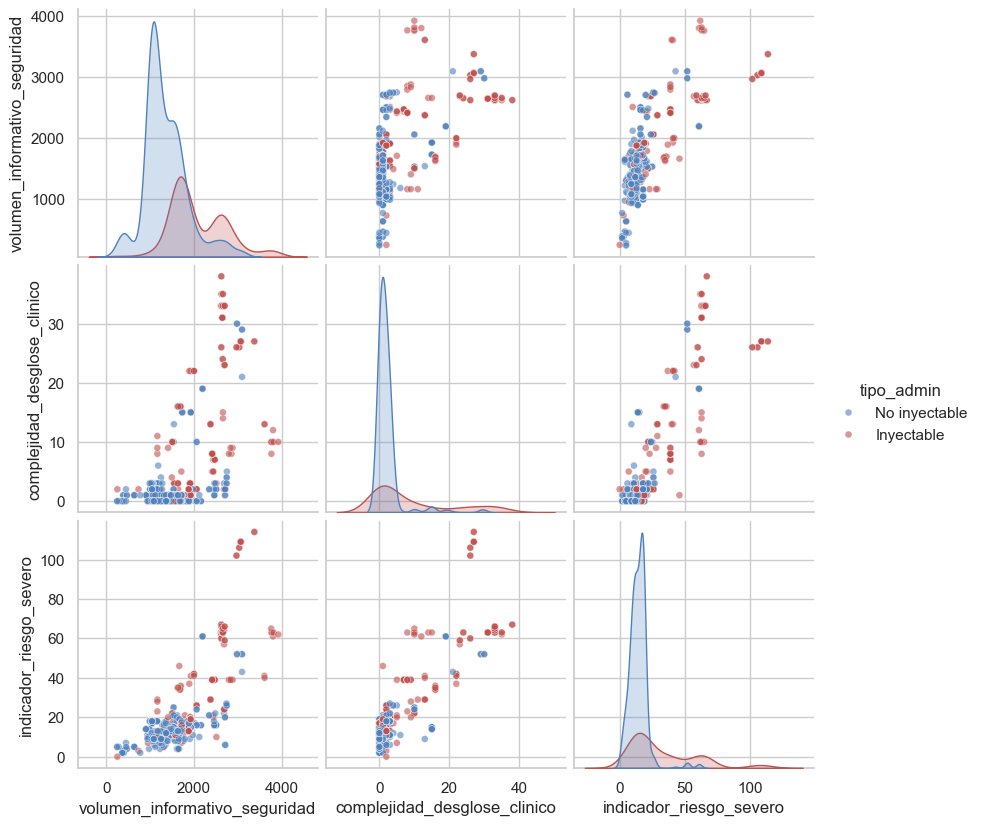

In [40]:
metricas = ["volumen_informativo_seguridad", "complejidad_desglose_clinico", "indicador_riesgo_severo", "Precio de referencia"]

sns.pairplot(df, vars=metricas[:3], hue="tipo_admin", palette=["#4f81bd", "#c0504d"],
             plot_kws={"alpha": 0.6, "s": 25}, height=2.8)
plt.show()

- Las tres métricas de la ficha técnica están positivamente correlacionadas, sobre todo el número de tablas con las menciones de "grave".
- Los "inyectables" tienen valores más elevados en las tres métricas (sus fichas son las más extensas, con más tablas y mayor mención de riesgo).
- Los medicamentos más antiguos tienden a tener fichas más cortas.

## 10. Análisis del precio

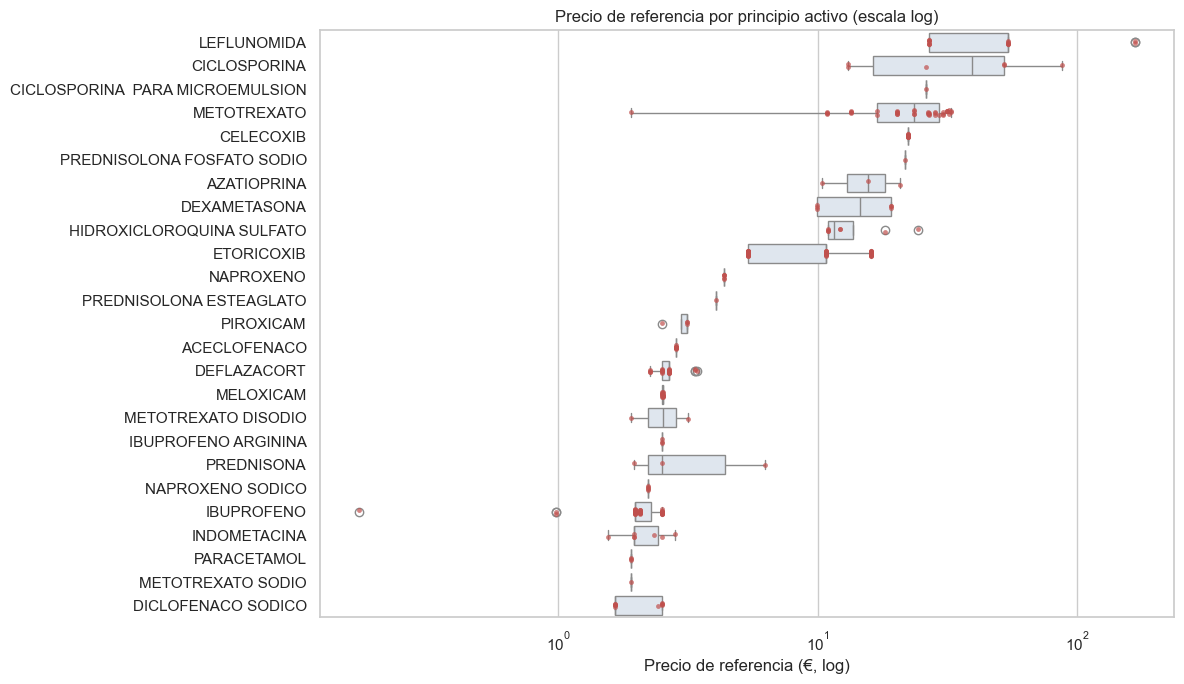

In [41]:
con_precio = df.dropna(subset=["Precio de referencia"])
orden = con_precio.groupby("pactivos")["Precio de referencia"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=con_precio, y="pactivos", x="Precio de referencia", order=orden, ax=ax, color="#dce6f1")
sns.stripplot(data=con_precio, y="pactivos", x="Precio de referencia", order=orden, ax=ax,
              color="#c0504d", size=3.5, alpha=0.7)
ax.set_xscale("log")
ax.set_title("Precio de referencia por principio activo (escala log)")
ax.set_xlabel("Precio de referencia (€, log)"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

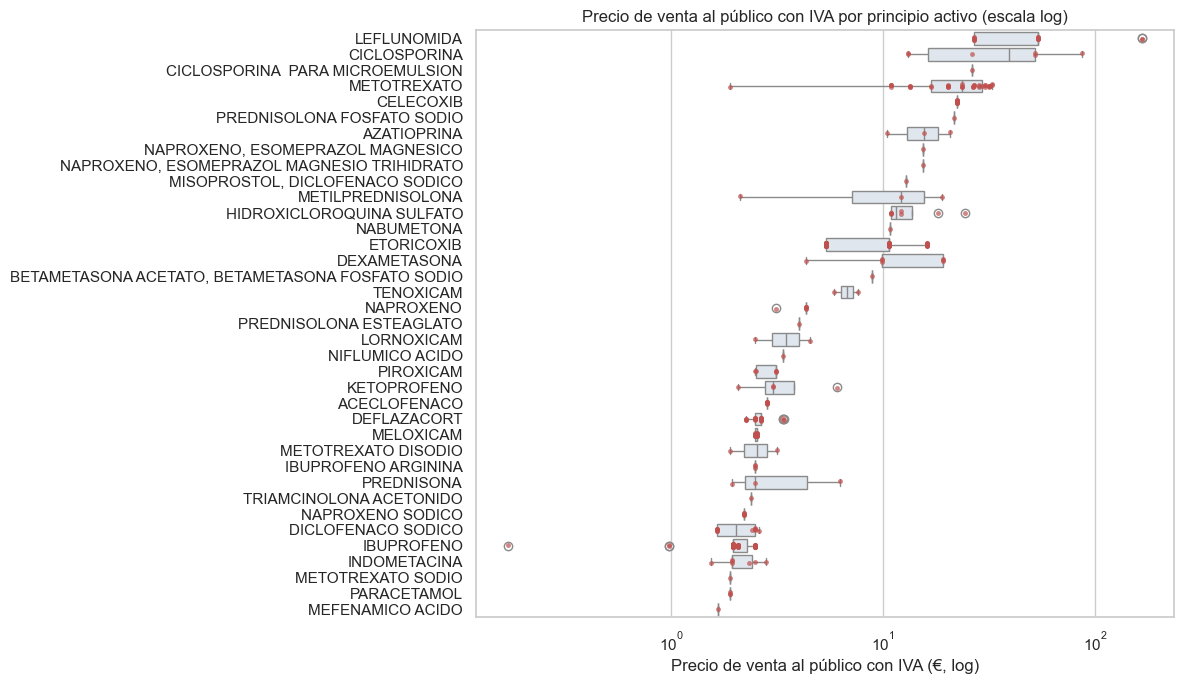

In [42]:
con_precio = df.dropna(subset=["Precio de venta al público con IVA"])
orden = con_precio.groupby("pactivos")["Precio de venta al público con IVA"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=con_precio, y="pactivos", x="Precio de venta al público con IVA", order=orden, ax=ax, color="#dce6f1")
sns.stripplot(data=con_precio, y="pactivos", x="Precio de venta al público con IVA", order=orden, ax=ax,
              color="#c0504d", size=3.5, alpha=0.7)
ax.set_xscale("log")
ax.set_title("Precio de venta al público con IVA por principio activo (escala log)")
ax.set_xlabel("Precio de venta al público con IVA (€, log)"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

Medicamentos con ambos precios: 316
Filas con diferencia distinta de 0: 0


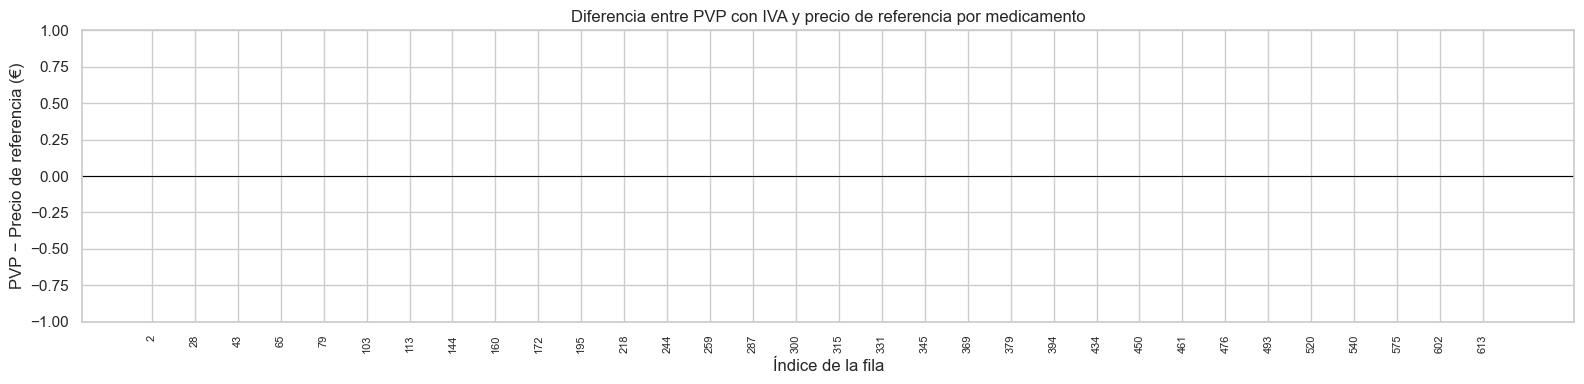

In [43]:
# Gráfico para mostrar las diferencias entre los precios
# Solo las filas que tienen los dos precios (si falta alguno, la diferencia no se puede calcular)
ambos = df[df["Precio de venta al público con IVA"].notna() & df["Precio de referencia"].notna()].copy()
ambos["dif_precio"] = ambos["Precio de venta al público con IVA"] - ambos["Precio de referencia"]

print("Medicamentos con ambos precios:", len(ambos))
print("Filas con diferencia distinta de 0:", (ambos["dif_precio"] != 0).sum())

# Color: rojo si el PVP es mayor, azul si es menor
colores = np.where(ambos["dif_precio"] > 0, "#c0504d", "#4f81bd")

fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(ambos.index.astype(str), ambos["dif_precio"], color=colores, width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Diferencia entre PVP con IVA y precio de referencia por medicamento")
ax.set_xlabel("Índice de la fila")
ax.set_ylabel("PVP − Precio de referencia (€)")

# Con más de 300 barras las etiquetas se solapan: se muestra una de cada 10
ax.set_xticks(range(0, len(ambos), 10))
ax.set_xticklabels(ambos.index[::10], rotation=90, fontsize=8)

# Si todas las diferencias son 0, se fija un rango para que el eje Y no quede vacío
if (ambos["dif_precio"] == 0).all():
    ax.set_ylim(-1, 1)

plt.tight_layout()
plt.show()

In [46]:
ambos['dif_precio'].describe()

count    316.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: dif_precio, dtype: float64

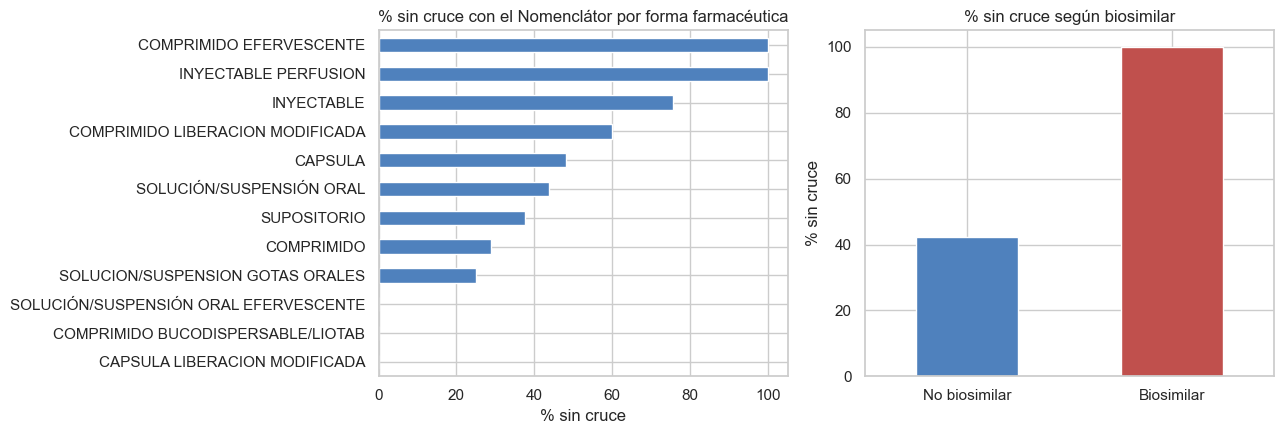

In [45]:
# Medicamentos sin cruce con el Nomenclátor, por forma farmacéutica y biosimilar
sin_cruce = df["Estado"].isna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(sin_cruce.groupby(df["forma_farmaceutica_simplificada"]).mean() * 100).sort_values() \
    .plot.barh(ax=axes[0], color="#4f81bd")
axes[0].set_title("% sin cruce con el Nomenclátor por forma farmacéutica")
axes[0].set_xlabel("% sin cruce"); axes[0].set_ylabel("")

(sin_cruce.groupby(df["biosimilar"]).mean() * 100).rename({0: "No biosimilar", 1: "Biosimilar"}) \
    .plot.bar(ax=axes[1], color=["#4f81bd", "#c0504d"])
axes[1].set_title("% sin cruce según biosimilar")
axes[1].set_ylabel("% sin cruce"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

- Los precios varían mucho entre los diferentes productos. En caso de usarse en el modelo deben ser estandarizados los datos para evitar que el precios obtenga un peso elevado en el modelo. Otra opción puede ser el eliminar los precios debido a la cantidad de valores que no se han encontrado en el Nomenclator.
- Ambas columnas de precio tienen el mismo valor para todas las filas en las que se encuentran ambos. Por ello se debe utilizar el `Precio de venta al público con IVA`como única referencia al precio en caso de incluirla en el modelo.

## 11. Exportar datos tratados

##